# Cell-membrane fluorescence recovery: measured transport inference

## Problem

An irregularly bleached membrane recovers slowly while repeated illumination continues to bleach fluorophores. Infer the lateral diffusivity and an optically resolved space–time recovery field. The unknown initial bleach profile is eliminated rather than supplied as an answer or treated as a noise-free first frame.

This review actively reconstructs the complete author-provided **42-frame** acquisition. Independent molecular truth is unavailable. Reproduced upstream measurements are explicitly labeled method references; their agreement with fresh local results is not biological accuracy. The author guide calls the included TIFF a FRAP experiment, but does not link this individual file to an organism/protein or microscope. The file's 30 s interval is preserved; it is not replaced by the 7–10 s timing of another series in the paper.

In [1]:
import os,sys,time,json,subprocess
from pathlib import Path
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
root=Path.cwd()
if not (root/'data/raw_data.npz').exists(): root=root.parent
os.chdir(root)
if str(root) not in sys.path: sys.path.insert(0,str(root))
import numpy as np
import matplotlib.pyplot as plt
from src.solvers import reconstruct
from src.physics_model import compression_matrix,profile_residual
from src.preprocessing import PIXEL_SIZE,TIME_STEP
from src.visualization import acquisition_figure,recovery_figure,model_figure,agreement
data=dict(np.load('data/raw_data.npz',allow_pickle=False))
upstream=dict(np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False))
oracle_models=dict(np.load('notebooks/reference_outputs/comparisons.npz',allow_pickle=False))
started=time.perf_counter()
fresh=reconstruct(data)
runtime=time.perf_counter()-started
print('Complete fresh reconstruction runtime (seconds):',runtime)
print('Input arrays:',{k:(v.shape,str(v.dtype)) for k,v in data.items()})

Complete fresh reconstruction runtime (seconds): 0.1930788000463508
Input arrays: {'movie': ((1, 42, 519, 408), 'uint16'), 'frap_coordinates': ((1, 89, 2), 'float32'), 'control_coordinates': ((1, 75, 2), 'float32')}


## Data

The movie retains its native uint16 camera intensities. The public centerlines describe observation-defined ROIs and contain no transport estimates. Each frame is sampled across a nine-pixel strip, using the original bilinear interpolation and triangular downsampling convention. Both extracted profiles match an independent ImageJ run pixel-for-pixel. The background is measured from a sample-free region, and an unbleached line estimates imaging loss independently of recovery. Camera units cannot be converted into molecular concentration with the available calibration.

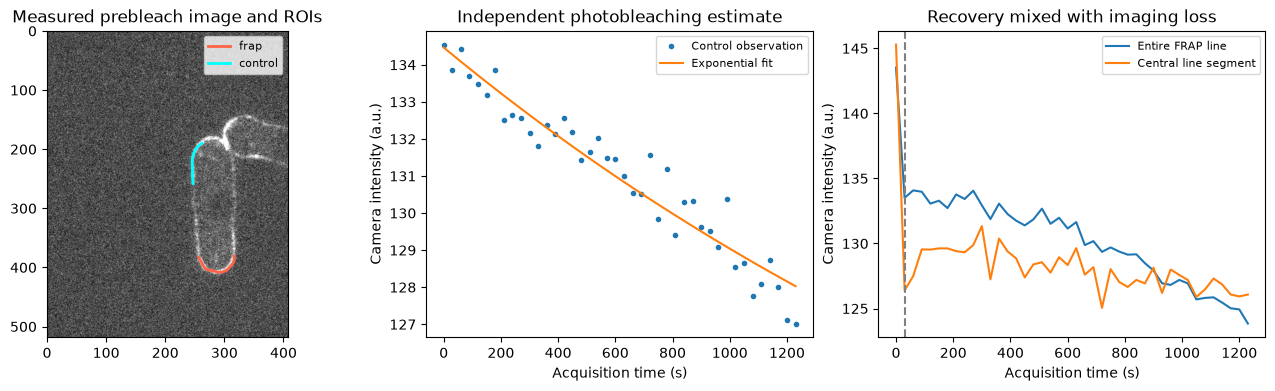

Imaging loss per frame: 0.009991926776494476
Normalized background: -0.9538538455963135


In [2]:
fig=acquisition_figure(data,fresh)
plt.show()
print('Imaging loss per frame:',fresh['epsilon'])
print('Normalized background:',float(fresh['preprocessing']['background']))

## Physics

Let $c(x,t)$ be fluorescence-proportional concentration along membrane arc length $x$, $D$ diffusivity and $t$ time. The transport equation is $\partial_t c=D\partial_x^2c$. Observed intensity is a Gaussian-blurred field multiplied by $e^{-\epsilon n}$, plus a constant camera background and noise; $n$ is the frame index and $\epsilon$ is imaging loss per frame. No periodic transport boundary is imposed.

The standard observation is represented in nine orthonormal real Fourier modes. For internal diffusivity $d=D\Delta t/\Delta x^2$, recovery-frame indices $i,j$ and pixel indices $x,z$, the uncompressed Gram kernel is

$$K_0(i,x,j,z)=\frac{e^{-(x-z)^2/[4(d(i+j)+1)]}}{\sqrt{4\pi(d(i+j)+1)}}e^{-\epsilon(i+j)}.$$

The unit constant is the original nominal one-pixel Gaussian optical-response convention. Compression acts on both spatial indices. The sum of the two times, rather than their difference, follows from eliminating the unknown initial field through $K=GG^T$, where $G$ maps that field into observations. Only its resolved optical projection is evaluated; poorly determined initial-field modes are not interpreted as molecular detail.

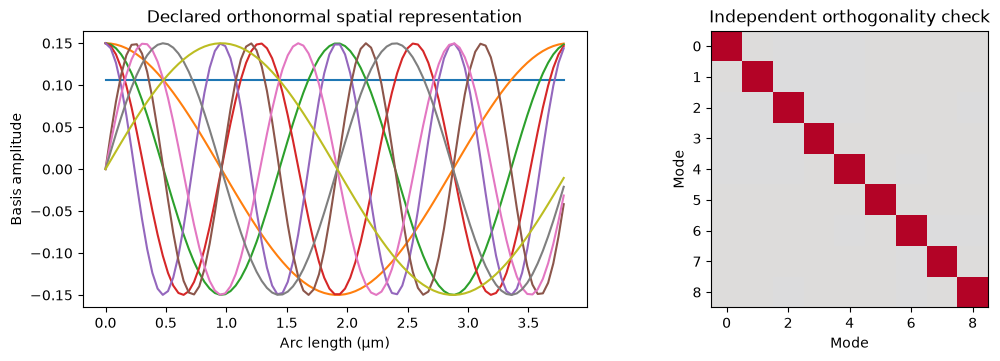

Maximum orthogonality error: 1.7763568394002505e-15


In [3]:
p=fresh['preprocessing']
c=compression_matrix(89)
fig,ax=plt.subplots(1,2,figsize=(11,3.5),layout='constrained')
ax[0].plot(np.arange(89)*float(PIXEL_SIZE),c.T)
ax[0].set(title='Declared orthonormal spatial representation',xlabel='Arc length (µm)',ylabel='Basis amplitude')
ax[1].imshow(c@c.T,vmin=-1,vmax=1,cmap='coolwarm')
ax[1].set(title='Independent orthogonality check',xlabel='Mode',ylabel='Mode')
plt.show()
print('Maximum orthogonality error:',np.max(abs(c@c.T-np.eye(9))))

## Method

For compressed observations $y$ after known offsets are removed, the residual projector is $P=\lambda(K+\lambda I)^{-1}$. The original numerical ridge is the largest singular value of $K$ times its dimension and float64 machine epsilon. The minimized cost is $\|Py\|^2/\mathrm{tr}(P^TP)$. Trust-region reflective least squares updates $D$, while each trial eliminates the initial field by linear algebra. The fitted observations are the original observations minus the unnormalized residual, transformed back to camera units.

The original kernel is nearly singular. Unconstrained ARPACK starting vectors produced an original-run diffusivity ensemble of approximately $5.92$–$6.15\times10^{-5}$ µm²/s, with almost unchanged residual cost. This execution supplies a documented ARPACK RNG convention. It preserves the original ridge and optimizer; stage parity, original-ensemble agreement and independent physics are all checked. Exact agreement of a seeded run alone would not validate the inverse problem.

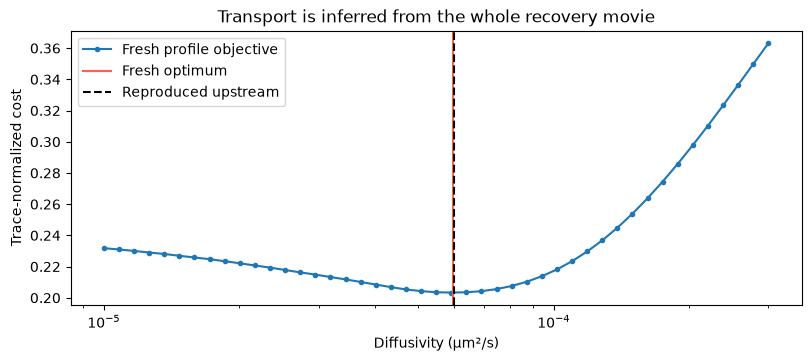

In [4]:
q=p['normalized']@c.T
grid=np.geomspace(1e-5,3e-4,45)
costs=[]
for D in grid:
    r=profile_residual(D*float(TIME_STEP)/float(PIXEL_SIZE)**2,q,fresh['epsilon'],p['background'])
    costs.append(float(r@r))
fig,ax=plt.subplots(figsize=(8,3.5),layout='constrained')
ax.semilogx(grid,costs,'o-',ms=3,label='Fresh profile objective')
ax.axvline(float(fresh['diffusivity'][0,0]),color='tomato',label='Fresh optimum')
ax.axvline(float(upstream['diffusivity'][0,0]),color='black',ls='--',label='Reproduced upstream')
ax.set(xlabel='Diffusivity (µm²/s)',ylabel='Trace-normalized cost',title='Transport is inferred from the whole recovery movie')
ax.legend();plt.show()

## Results

The comparison below preserves the scientific distinction between measured data, compressed observations, reproduced original-method measurements, and a newly computed local fit. All plots share the camera-intensity scale. Residuals compare fresh model output with the observations, not with an invented truth image.

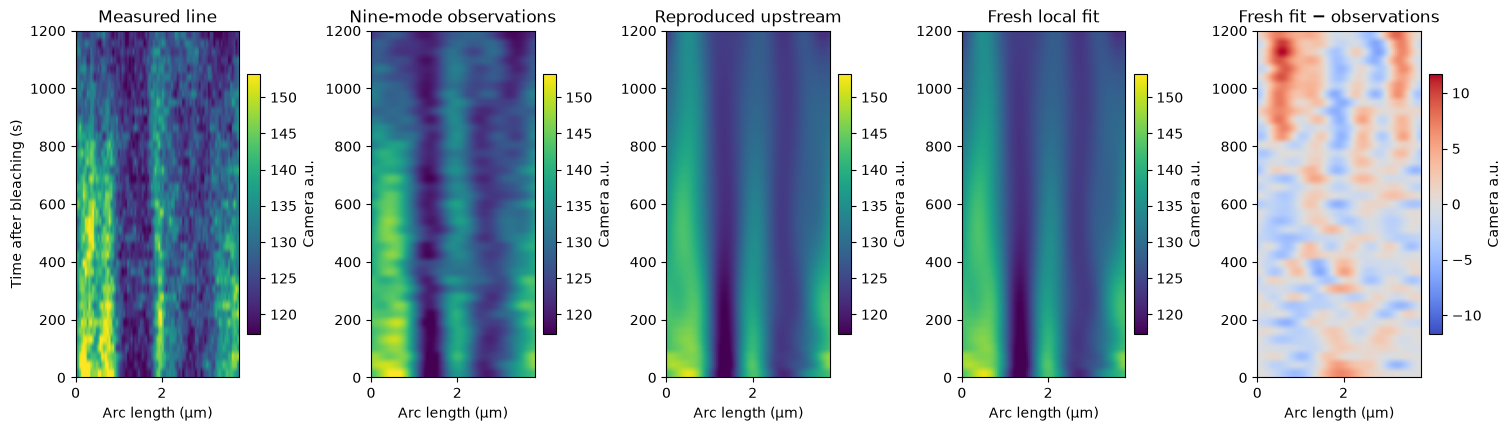

Fresh diffusivity (µm²/s): 5.972747858553252e-05
Reproduced upstream diffusivity (µm²/s): 5.993295324677043e-05
Field NCC, range-NRMSE: (0.9999999992942029, 0.0001297644865760305)
Relative diffusivity difference: 0.0034284087485541015
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999992942029,
    "nrmse": 0.0001297644865760305,
    "diffusivity_relative_error": 0.0034284087485541015
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.003
    },
    "diffusivity_relative_error": {
      "comparison": "<=",
      "boundary": 0.05
    }
  },
  "errors": []
}



In [5]:
fig=recovery_figure(fresh,upstream['reconstruction'])
plt.show()
print('Fresh diffusivity (µm²/s):',float(fresh['diffusivity'][0,0]))
print('Reproduced upstream diffusivity (µm²/s):',float(upstream['diffusivity'][0,0]))
print('Field NCC, range-NRMSE:',agreement(fresh['reconstruction'],upstream['reconstruction']))
print('Relative diffusivity difference:',float(abs(fresh['diffusivity'][0,0]/upstream['diffusivity'][0,0]-1)))
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh['reconstruction'],diffusivity=fresh['diffusivity'])
run=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
print(Path('output/judge_report.json').read_text(encoding='utf8'))
assert run.returncode==0,run.stderr

### Biological model comparison on the same measured movie

The paper compares pure diffusion, reaction-only and reaction-diffusion explanations. All three are actively fitted here. The reaction equation adds a source and loss term; the prebleach stationary level ties source to loss. A negative inferred loss is a diagnostic of model inadequacy, not a physically admissible removal process. Reaction parameters and weak profile modes can be substantially less stable than the visible field, so both original and fresh costs and fields are shown. Historical paper-average parameter tables concern a different experimental ensemble and are not relabeled as measurements of this file.

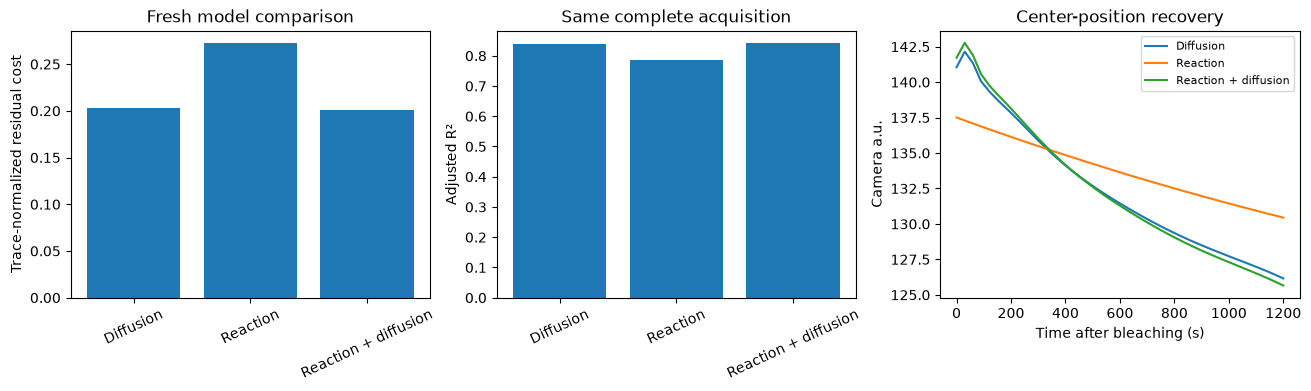

Method | fresh cost | original cost | fresh adjusted R² | loss (1/s) | field NRMSE to original
Diffusion 0.20330644810086113 0.2032763322763038 0.839682783507744 0.0 0.0001297644865760305
Reaction 0.27220488035989765 0.27230504443700476 0.7847949611481998 5.362620472838898e-05 0.007472833662365762
Reaction + diffusion 0.20101537212976514 0.20092068016099024 0.8410149815314187 -7.3887854169521e-05 0.002011756298404813
A negative reaction-diffusion loss is physically inadmissible; pure diffusion remains the selected model.


In [6]:
models={'Diffusion':fresh,'Reaction':reconstruct(data,model='reaction'),'Reaction + diffusion':reconstruct(data,model='reaction-diffusion')}
fig=model_figure(models);plt.show()
print('Method | fresh cost | original cost | fresh adjusted R² | loss (1/s) | field NRMSE to original')
for label,k in [('Diffusion',1),('Reaction',3),('Reaction + diffusion',2)]:
    r=models[label]
    print(label,r['cost'],float(oracle_models[f'model{k}_diagnostics'][2]),r['r2'],r['loss_rate'],agreement(r['reconstruction'][0],oracle_models[f'model{k}_field'])[1])
print('A negative reaction-diffusion loss is physically inadmissible; pure diffusion remains the selected model.')

### Acquisition-loss ablation and residual examination

The following fit deliberately ignores independently observed imaging loss. It is an explicitly labeled ablation, not a replacement acquisition or a new task. Histogram and time traces assess the actual residual pattern; no calibrated Gaussian-noise or chi-square significance is claimed.

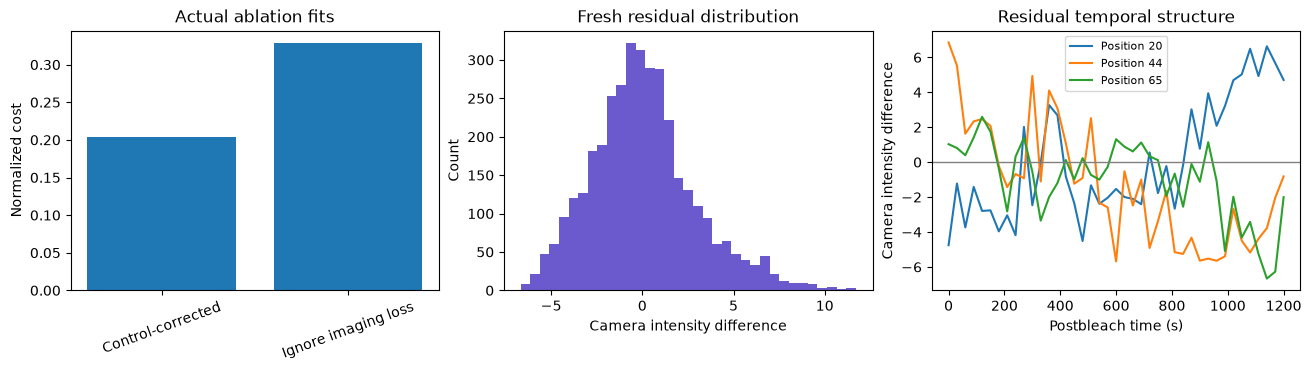

Corrected D, ablated D (µm²/s): 5.972747858553252e-05 9.638023468325415e-05


In [7]:
ablated=reconstruct(data,ignore_bleaching=True)
projected=p['normalized']@c.T@c*p['norm'][1]+p['norm'][0]
residual=fresh['reconstruction'][0]-projected
fig,ax=plt.subplots(1,3,figsize=(13,3.6),layout='constrained')
ax[0].bar(['Control-corrected','Ignore imaging loss'],[fresh['cost'],ablated['cost']]);ax[0].tick_params(axis='x',labelrotation=20);ax[0].set(title='Actual ablation fits',ylabel='Normalized cost')
ax[1].hist(residual.ravel(),bins=35,color='slateblue');ax[1].set(title='Fresh residual distribution',xlabel='Camera intensity difference',ylabel='Count')
for j in [20,44,65]:ax[2].plot(np.arange(41)*30,residual[:,j],label=f'Position {j}')
ax[2].axhline(0,color='gray',lw=1);ax[2].set(title='Residual temporal structure',xlabel='Postbleach time (s)',ylabel='Camera intensity difference');ax[2].legend(fontsize=8)
plt.show()
print('Corrected D, ablated D (µm²/s):',float(fresh['diffusivity'][0,0]),float(ablated['diffusivity'][0,0]))
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=fresh['reconstruction'],diffusivity=fresh['diffusivity'],cost=np.array(fresh['cost']),runtime_seconds=np.array(runtime),reaction_field=models['Reaction']['reconstruction'],reaction_diffusion_field=models['Reaction + diffusion']['reconstruction'],ablation_field=ablated['reconstruction'])

## Conclusion

The full observed movie supports a slow-transport reconstruction under the selected diffusion model. ImageJ sampling and deterministic kernel stages have independent numerical fixtures, and the fresh solver passes the standalone field-plus-diffusivity evaluator. The comparison retains the reaction alternatives and shows why a numerically improved but negative-loss fit is not a physical explanation.

The main limitations are uncalibrated absolute fluorescence, nominal rather than measured optical blur, an infinite-line approximation, weak initial-profile modes and sensitivity of the original near-machine-precision inverse to numerical conventions. The author-supplied experimental TIFF is traceable, but its per-file organism and instrument identity are unavailable. The reconstructed optical field is a method result, not independently measured molecular truth. The canonical notebook contains fresh execution outputs; archived measurements serve only as labeled comparisons.